In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Leemos los csv creados en mainpisa y guardados en la carpeta datos
df_valencia25=pd.read_csv('data/pisa_valencia25.csv')
df_valencia22=pd.read_csv('data/pisa_valencia22.csv')
df_valencia18=pd.read_csv('data/pisa_valencia18.csv')

In [3]:
def pct_inmigracion(df):
    # Base: alumnos con IMMIG válido (1, 2 o 3) y peso NO NULO
    d = df[df["IMMIG"].isin([1, 2, 3])].dropna(subset=["W_FSTUWT"])
    w = d["W_FSTUWT"]
    return {
        "Nativos":       100 * w[d["IMMIG"] == 1].sum() / w.sum(),
        "2ª generación": 100 * w[d["IMMIG"] == 2].sum() / w.sum(),
        "1ª generación": 100 * w[d["IMMIG"] == 3].sum() / w.sum(),
    }

tabla_inmig = pd.DataFrame({
    "2018": pct_inmigracion(df_valencia18),
    "2022": pct_inmigracion(df_valencia22),
    "2025": pct_inmigracion(df_valencia25),
})
print(tabla_inmig.round(1))

               2018  2022  2025
Nativos        86.0  82.9  72.4
2ª generación   5.5   9.2  11.5
1ª generación   8.5   7.9  16.1


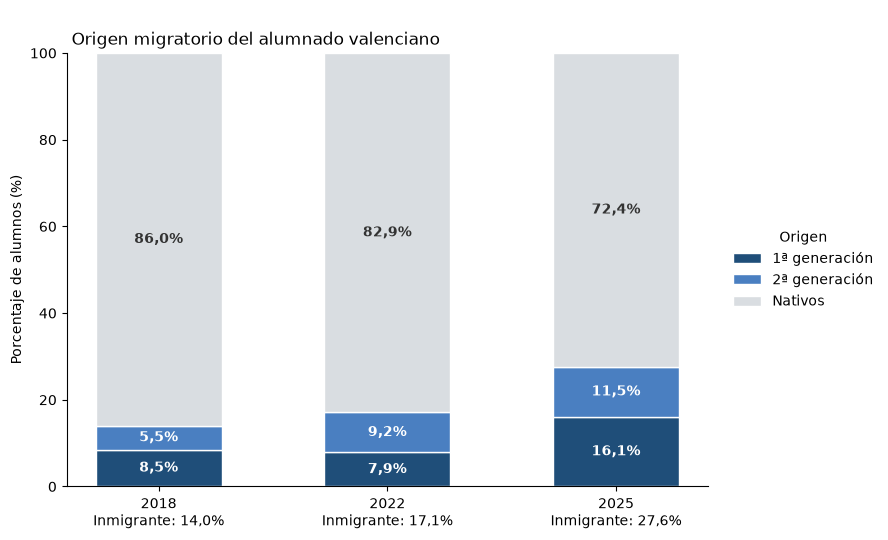

In [8]:
# 2) Orden de apilado, de abajo arriba: primera gen., segunda gen., nativos
orden = ["1ª generación", "2ª generación", "Nativos"]
colores = {"1ª generación": "#1f4e79", "2ª generación": "#4a7fc1", "Nativos": "#d9dde1"}
tabla = tabla_inmig.loc[orden]
 
anios = list(tabla.columns)                       # 2018, 2022, 2025 (izquierda a derecha)
x = np.arange(len(anios))
 
fig, ax = plt.subplots(figsize=(9, 5.5))
fondo = np.zeros(len(anios))                      # altura a la que empieza cada tramo
 
for categoria in orden:
    valores = tabla.loc[categoria].values
    ax.bar(x, valores, bottom=fondo, width=0.55, color=colores[categoria],
           label=categoria, edgecolor="white")
    for xi, v, f in zip(x, valores, fondo):       # % dentro de cada tramo
        color_texto = "#333333" if categoria == "Nativos" else "white"
        ax.text(xi, f + v / 2, f"{v:.1f}%".replace(".", ","), ha="center", va="center",
                fontsize=10, fontweight="bold", color=color_texto)
    fondo = fondo + valores
 
# 3) El total de alumnado inmigrante (1ª + 2ª gen.) va bajo cada año
totales = tabla.loc[["1ª generación", "2ª generación"]].sum()
ax.set_xticks(x)
ax.set_xticklabels([f"{a}\nInmigrante: {totales[a]:.1f}%".replace(".", ",") for a in anios])
 
ax.set_ylim(0, 100)
ax.set_ylabel("Porcentaje de alumnos (%)")
ax.set_title(" \n Origen migratorio del alumnado valenciano", loc="left")
ax.legend(title="Origen", loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
 
fig.tight_layout()
plt.savefig("imgs/grafico_inmigracion.png", dpi=200, bbox_inches="tight")
plt.show()

In [6]:
pv_cols=[f"PV{i}READ" for i in range(1, 11)] 

def media_pond(notas, pesos):
    return (notas * pesos).sum() / pesos.sum()

def lectura_por_grupo(df, pv_cols):
    # Alumnos con origen migratorio válido y con todos los datos necesarios
    d = df[df["IMMIG"].isin([1, 2, 3])].dropna(subset=["W_FSTUWT"] + pv_cols)

    nombres = {1: "Nativos", 2: "2ª generación", 3: "1ª generación"}
    medias_grupo = {}
    length_grupo = {}
    for codigo, nombre in nombres.items():
        grupo = d[d["IMMIG"] == codigo]
        # media ponderada con cada PV, y luego el promedio de las 10
        medias = [media_pond(grupo[pv], grupo["W_FSTUWT"]) for pv in pv_cols]
        medias_grupo[nombre] = np.mean(medias)
        length_grupo[nombre] = len(grupo)
    return medias_grupo, length_grupo

lect18, n18_g = lectura_por_grupo(df_valencia18, pv_cols)
lect22, n22_g = lectura_por_grupo(df_valencia22, pv_cols)
lect25, n25_g = lectura_por_grupo(df_valencia25, pv_cols)

print(pd.DataFrame({"2018": lect18, "2022": lect22, "2025": lect25}).round(1))
print(pd.DataFrame({"2018": n18_g, "2022": n22_g, "2025": n25_g}))

                2018   2022   2025
Nativos        480.1  488.9  439.5
2ª generación  464.5  479.4  420.5
1ª generación  440.6  450.8  390.0
               2018  2022  2025
Nativos        1474  1309  1176
2ª generación    90   140   188
1ª generación   130   113   253
